In [ ]:
# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — Gate C liveness (`gate-current-sanity-check`)

Four legs at B = 0, T = 1.15 K, I_bias = 5 nA (0.5 V / 100 MΩ): TG 0→+3 V, TG 0→−3 V, BG 0→+4.5 V, BG 0→−4.5 V — each to its committed SAFETIES limit, other gate parked at 0, Si at 0, `nplci=10` for pA gate-current readback.


run 0 TG 0->+3 V: I_drain 4.98-5.00 nA, |I_tg|max 41 pA, |I_bg|max 109 pA, interrupted=False
run 1 TG 0->-3 V: I_drain 4.98-5.00 nA, |I_tg|max 30 pA, |I_bg|max 109 pA, interrupted=False
run 2 BG 0->+4.5 V: I_drain 4.98-5.01 nA, |I_tg|max 33 pA, |I_bg|max 108 pA, interrupted=False
run 3 BG 0->-4.5 V: I_drain 4.98-5.00 nA, |I_tg|max 32 pA, |I_bg|max 112 pA, interrupted=False


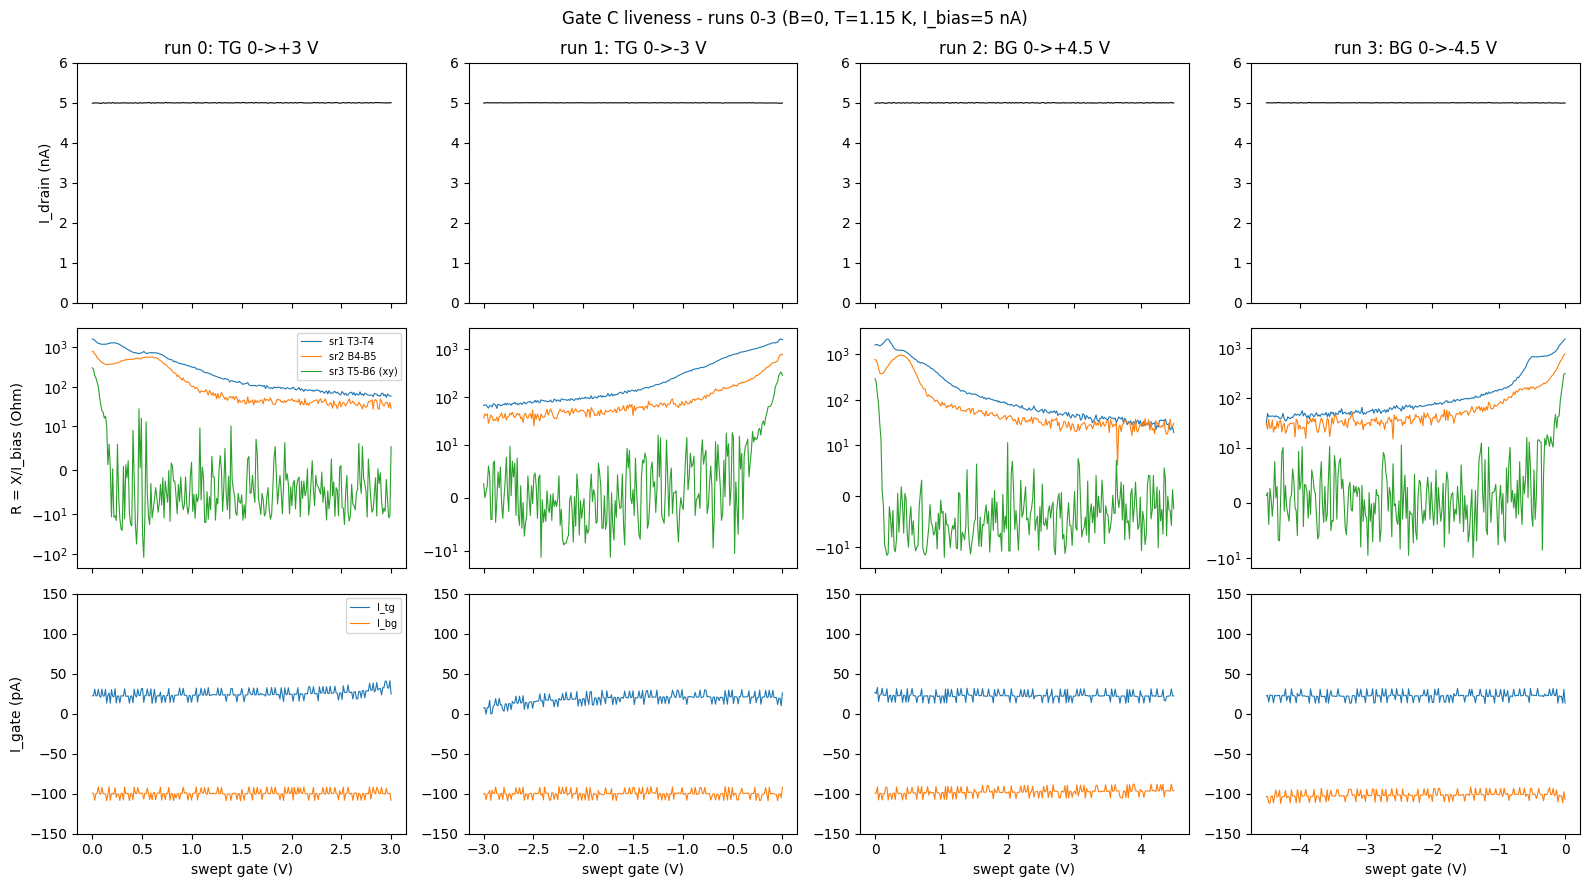

In [3]:
# Gate C — raw traces + gate currents, runs 0-3
I_BIAS = 5e-9
SR0_GAIN = -1e6
LEGS = [(0, "TG 0->+3 V", "k_2400_tg_volt"), (1, "TG 0->-3 V", "k_2400_tg_volt"),
        (2, "BG 0->+4.5 V", "k_2400_bg_volt"), (3, "BG 0->-4.5 V", "k_2400_bg_volt")]

fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex="col")
for j, (rid, title, swept) in enumerate(LEGS):
    r = run(rid)
    v = r.col_at(r.col_indices(swept)[0])
    itg = r.col_at(r.col_indices("k_2400_tg_curr")[-1])
    ibg = r.col_at(r.col_indices("k_2400_bg_curr")[-1])
    i_drain = r.col_at(r.col_indices("sr0_X")[-1]) / SR0_GAIN

    axes[0, j].plot(v, i_drain * 1e9, lw=0.8, color="k")
    axes[0, j].set_title(f"run {rid}: {title}")
    axes[0, j].set_ylim(0, 6)

    for ch, lbl in (("sr1_X", "sr1 T3-T4"), ("sr2_X", "sr2 B4-B5"), ("sr3_X", "sr3 T5-B6 (xy)")):
        x = r.col_at(r.col_indices(ch)[-1])
        axes[1, j].plot(v, x / I_BIAS, lw=0.8, label=lbl)
    axes[1, j].set_yscale("symlog", linthresh=10)

    axes[2, j].plot(v, itg * 1e12, lw=0.8, label="I_tg")
    axes[2, j].plot(v, ibg * 1e12, lw=0.8, label="I_bg")
    axes[2, j].set_ylim(-150, 150)
    axes[2, j].set_xlabel("swept gate (V)")

    print(f"run {rid} {title}: I_drain {i_drain.min()*1e9:.2f}-{i_drain.max()*1e9:.2f} nA, "
          f"|I_tg|max {abs(itg).max()*1e12:.0f} pA, |I_bg|max {abs(ibg).max()*1e12:.0f} pA, "
          f"interrupted={r.interrupted}")

axes[0, 0].set_ylabel("I_drain (nA)")
axes[1, 0].set_ylabel("R = X/I_bias (Ohm)")
axes[1, 0].legend(fontsize=7)
axes[2, 0].set_ylabel("I_gate (pA)")
axes[2, 0].legend(fontsize=7)
fig.suptitle("Gate C liveness - runs 0-3 (B=0, T=1.15 K, I_bias=5 nA)")
fig.tight_layout()


**Read — Gate C verdict: PASS.** All four legs complete (251/251 rows each), none interrupted.

- **Alive**: the full 5 nA bias flows on every leg across the whole swept window (drain never drops); sr1/sr2 four-terminal channels respond smoothly to both gates; sr3 (Hall) sits at ±10 Ω noise around zero at B = 0 as it should.
- **Safe**: swept-gate currents ≤ 41 pA to every card limit, riding the capacitive charging slope — no leakage turn-up on any leg. Parked-gate currents are flat, static offsets (I_tg ≈ +25 pA, I_bg ≈ −100 pA readback offsets — never tracking the swept gate → no cross-gate path). The −100 pA scale on the BG Keithley is a readback offset to remember when reading leakage plots near threshold this session.
- **Free physics**: both positive-gate legs show a resistance maximum near +0.4–0.6 V on the swept gate (sr1 peaking ~1.3 kΩ), and the negative legs rise monotonically toward 0 V — the CNP ridge sits just electron-side of the origin, well inside the gate windows. The peak R is modest (kΩ), noted without interpretation — the gate map will show the full ridge.

**Gate C closed.** The provided contact configuration is live on all channels and the gates are clean to their committed limits, both polarities. → Investigation Step 1: 0 T gate map (`gatemap`) for the CNP line and (n, D) calibration.


## Run 4 — 0 T gate map + CNP-line calibration (`cnp-and-dline-calibration`)

61 × 121 map, BG slow ±3 V / TG fast ±3 V, B = 0, T = 1.15 K, I_bias = 5 nA. Ridge extracted per channel (row-wise argmax, gaussian-smoothed; railed rows → plateau center; edge-clipped rows dropped; iterative 2σ outlier rejection). **Axis orientation: ridge position is V_tg (fast) fitted against V_bg (slow row coordinate)** — slope = dV_tg/dV_bg = −c_bg/c_tg.


sr1: slope -1.2650, intercept +0.0384 V, resid rms 19.5 mV, rows 35/61
sr2: slope -1.2899, intercept +0.0303 V, resid rms 17.7 mV, rows 41/61
ratio c_bg/c_tg = 1.2774 (geometry prior 1.300); c_tg = 1.7027e-03 (anchor), c_bg = 2.1751e-03 F/m^2
intercept b = +0.0343 V -> n_offset = -0.0365 e12 cm^-2; D_offset = 0 (assumed, no locating feature)
D=0.0: realized n-window -6.40 .. +6.34 e12 cm^-2
D=0.2: realized n-window -8.00 .. +4.12 e12 cm^-2
D=0.4: realized n-window -7.82 .. +1.90 e12 cm^-2


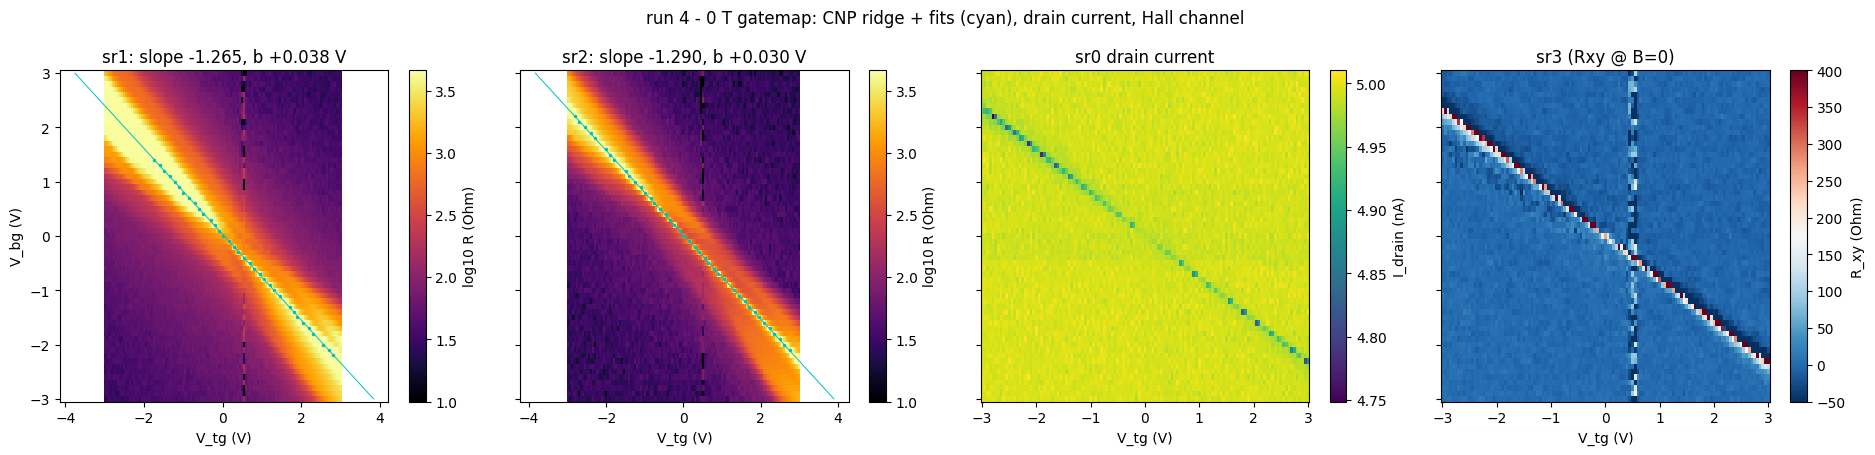

In [4]:
# Run 4 — map re-form, ridge fits, calibration (proven in hera_scratch/cnp_cal2.py)
from scipy.ndimage import gaussian_filter1d
from scipy.constants import epsilon_0, e as qe
from sharpelab_nb.gates import calc_gate_voltages

r4 = run(4)
fg = fan_grids(r4)
rg = resistance_grids(fg)
vbg = fg.slow
vtg = np.asarray(fg.grid("k_2400_tg_volt"))[0]
RAIL = 4.3e3  # sr1-3 sens 2e-5 rails at ~4.37 kOhm @ 5 nA

def extract_ridge(ch):
    R = np.asarray(rg.R[ch]); ridge, keep = [], []
    for i in range(R.shape[0]):
        row = gaussian_filter1d(R[i], 2); j = int(np.argmax(row))
        if np.sum(R[i] > RAIL) >= 3:
            idx = np.where(R[i] > RAIL)[0]
            if idx.max() - idx.min() < 20: j = int(np.round(idx.mean()))
            else: ridge.append(np.nan); keep.append(False); continue
        ridge.append(vtg[j]); keep.append(2 < j < len(row) - 3)
    ridge, keep = np.array(ridge), np.array(keep)
    k = keep & np.isfinite(ridge)
    for _ in range(4):
        p = np.polyfit(vbg[k], ridge[k], 1)
        res = ridge - np.polyval(p, vbg); s = np.nanstd(res[k])
        k2 = keep & np.isfinite(ridge) & (np.abs(res) < 2 * s)
        if k2.sum() == k.sum(): break
        k = k2
    return ridge, k, p, float(np.nanstd(res[k]))

fits = {ch: extract_ridge(ch) for ch in ("sr1", "sr2")}
for ch, (_, k, p, rms) in fits.items():
    print(f"{ch}: slope {p[0]:+.4f}, intercept {p[1]:+.4f} V, resid rms {rms*1e3:.1f} mV, rows {k.sum()}/61")

# calibration: anchor c_tg at geometry (15.6 nm hBN); ratio + intercept from data (channel mean)
c_tg = epsilon_0 * 3 / 15.6e-9
ratio = -np.mean([fits["sr1"][2][0], fits["sr2"][2][0]])
c_bg = ratio * c_tg
b = np.mean([fits["sr1"][2][1], fits["sr2"][2][1]])
n_offset = -c_tg * b / qe                    # SI m^-2 (hera GateCalibration convention)
cal = GateCalibration(c_tg, c_bg, n_offset=n_offset)   # session calibration, D_offset = 0 (stated assumption)
n_off_e12 = n_offset * 1e-16                 # sharpelab_nb.gates convention (1e12 cm^-2)
print(f"ratio c_bg/c_tg = {ratio:.4f} (geometry prior 1.300); c_tg = {c_tg:.4e} (anchor), c_bg = {c_bg:.4e} F/m^2")
print(f"intercept b = {b:+.4f} V -> n_offset = {n_off_e12:+.4f} e12 cm^-2; D_offset = 0 (assumed, no locating feature)")
ns_test = np.linspace(-8, 8, 801)
for D0 in (0.0, 0.2, 0.4):
    Vt, Vb = calc_gate_voltages(ns_test, D0*np.ones_like(ns_test), c_tg, c_bg, n_offset=n_off_e12)
    ok = (np.abs(Vt) <= 3.0) & (np.abs(Vb) <= 4.5)
    print(f"D={D0}: realized n-window {ns_test[ok].min():+.2f} .. {ns_test[ok].max():+.2f} e12 cm^-2")

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6), sharey=True)
for ax, ch in zip(axes[:2], ("sr1", "sr2")):
    R = np.asarray(rg.R[ch]); rv, k, p, _ = fits[ch]
    pm = ax.pcolormesh(vtg, vbg, np.log10(np.clip(R, 10, None)), cmap="inferno", shading="auto")
    plt.colorbar(pm, ax=ax, label="log10 R (Ohm)")
    ax.plot(rv[k], vbg[k], "c.", ms=3); ax.plot(np.polyval(p, vbg), vbg, "c-", lw=0.7)
    ax.set_title(f"{ch}: slope {p[0]:+.3f}, b {p[1]:+.3f} V"); ax.set_xlabel("V_tg (V)")
pm = axes[2].pcolormesh(vtg, vbg, np.asarray(rg.current)*1e9, cmap="viridis", shading="auto")
plt.colorbar(pm, ax=axes[2], label="I_drain (nA)"); axes[2].set_title("sr0 drain current"); axes[2].set_xlabel("V_tg (V)")
pm = axes[3].pcolormesh(vtg, vbg, np.clip(np.asarray(rg.R["sr3"]), -50, 400), cmap="RdBu_r", shading="auto")
plt.colorbar(pm, ax=axes[3], label="R_xy (Ohm)"); axes[3].set_title("sr3 (Rxy @ B=0)"); axes[3].set_xlabel("V_tg (V)")
axes[0].set_ylabel("V_bg (V)")
fig.suptitle("run 4 - 0 T gatemap: CNP ridge + fits (cyan), drain current, Hall channel")
fig.tight_layout()


**Read — calibration established (two-tier provenance).**

- **Ratio (data-calibrated)**: c_bg/c_tg = 1.2774 (sr1 −1.2650, sr2 −1.2899; 2 % cross-channel spread, larger than the per-channel fit error → possibly mild spatial variation between the T3–T4 and B4–B5 regions; per-channel numbers kept above, channel mean used for the device calibration). Geometry-sanity: prior ratio 15.6/12 = 1.300 — agreement to 1.7 %, well inside the tens-of-percent alarm band.
- **Absolute scale (geometry prior)**: c_tg anchored at the 15.6 nm hBN stack value (both gates are simple hBN; TG anchored, BG set by the fitted ratio). Upgrade path: quantum-Hall lever-arm check when fan data lands — ray slopes must quantize (dn/dB = ν·e/h).
- **Offsets**: n_offset = −0.036×10¹² cm⁻² (tiny intrinsic doping, CNP at V_tg ≈ +0.034 V); D_offset = 0 — *assumed*, no feature yet physically locates D = 0.
- **Quality**: ridge-to-fit rms < 20 mV ⇒ δn ≈ 0.02×10¹² cm⁻². Railed rows (2e-5 rail = 4.37 kΩ) handled by plateau-centering; CNP peak R above the rail is *unmeasured* here (floor: R_CNP ≥ 4.4 kΩ at |D| ≳ 0.2 V/nm, rising with |D|; un-railed near D ≈ 0 at ~1.5 kΩ).
- **Realized D = 0 window**: n ∈ [−6.4, +6.3]×10¹² cm⁻² inside the validators — comfortably covers the SdH operating densities.
- **Region survey**: both hole and electron sides metallic (R_xx < 130 Ω at |n| > 2×10¹²) on both channels; drain current ≥ 4.75 nA everywhere → no insulating contact arms in the window. One feature: a **vertical stripe at V_tg ≈ +0.55 V** (TG-only-gated arm regions at neutrality), crossing D = 0 at n ≈ +1.2×10¹² cm⁻² — a known series-R artifact line for electron-side columns, not a bulk feature.

**Next** (investigation Step 2→3): F_L(6×10¹²) = 62 T → Δ(1/B) = 1/(3F_L) ≈ 5.4×10⁻³ T⁻¹; SdH spot checks at n = −6 and +6 (D = 0), uniform in 1/B over [0.25, 8] T.


## Run 5 — SdH spot check, hole side (n_target = −6×10¹², D = 0, B 0.25→8 T uniform-1/B)

`sdh-spot-check`, I_bias = 20 nA, sens sr1/sr2 2e-5 (1 kΩ ceiling — max 770 Ω, no clipping), 721 pts, Δ(1/B) = 5.4×10⁻³ T⁻¹, T = 1.15–1.18 K.


Hall slope 97.8 Ohm/T -> |n| = 6.38 e12 cm^-2 (target 6.00; geometry scale ~+6%)
F_L(true n) = 66.0 T   [F_L(design n) = 62.0 T]
sr1 FFT [3.0,8] deg5: peaks ['12.7 T (1.00)', '24.0 T (0.46)', '33.4 T (0.65)', '58.1 T (0.70)', '73.7 T (0.43)', '83.8 T (0.15)']
sr1 FFT [3.5,8] deg4: peaks ['13.4 T (1.00)', '30.8 T (0.76)', '57.0 T (0.74)', '71.9 T (0.53)', '91.5 T (0.20)']
sr1 FFT [4.0,8] deg3: peaks ['19.2 T (1.00)', '27.2 T (0.99)', '57.7 T (0.82)', '71.5 T (0.61)']
sr1 FFT [4.5,8] deg3: peaks ['24.7 T (1.00)', '62.4 T (0.78)']


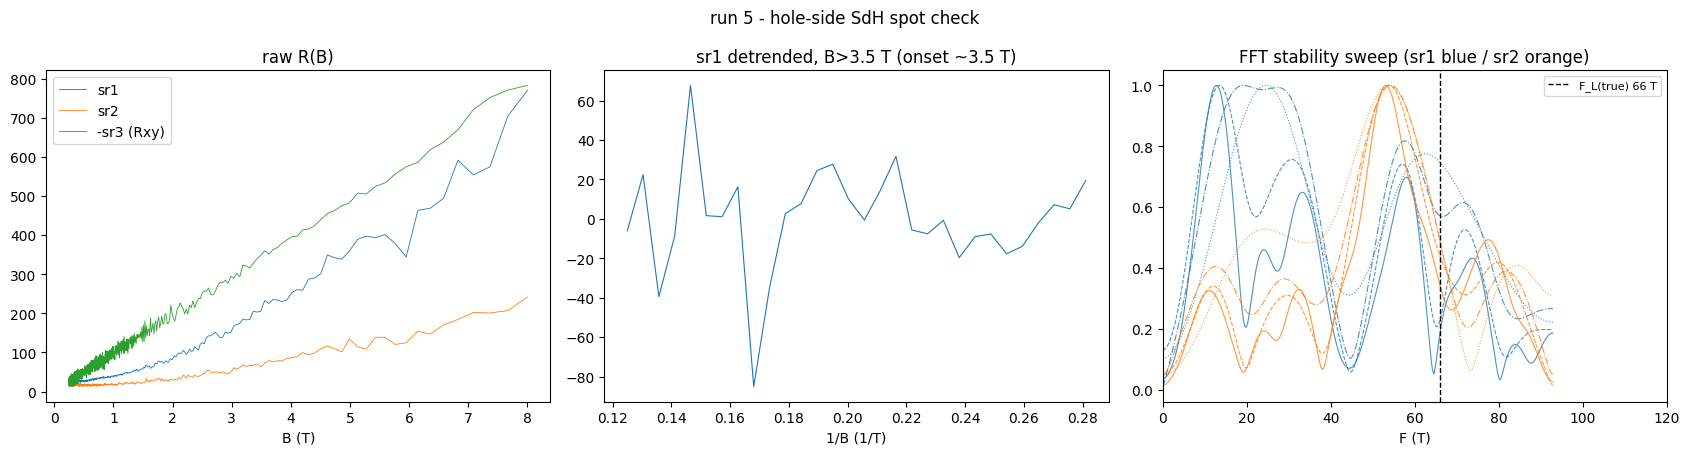

In [5]:
# Run 5 — raw record, Hall density pin, SdH FFT stability sweep
from scipy.signal import find_peaks

r5 = run(5)
B5 = r5.col("magnet_field")
I5 = 20e-9
R5 = {ch: r5.col_at(r5.col_indices(f"{ch}_X")[-1]) / I5 for ch in ("sr1", "sr2", "sr3")}

# Hall density pin (independent of lever arm): n = B / (e * R_xy), low-B slope
m_hall = (B5 > 0.4) & (B5 < 1.5)
p_hall = np.polyfit(B5[m_hall], -R5["sr3"][m_hall], 1)
n_hall = 1 / (cst.e * p_hall[0])
F_L_true = (cst.h / (4 * cst.e)) * n_hall
print(f"Hall slope {p_hall[0]:.1f} Ohm/T -> |n| = {n_hall*1e-16:.2f} e12 cm^-2 "
      f"(target 6.00; geometry scale ~{(n_hall/6e16-1)*100:+.0f}%)")
print(f"F_L(true n) = {F_L_true:.1f} T   [F_L(design n) = 62.0 T]")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(B5, R5["sr1"], lw=0.6, label="sr1")
axes[0].plot(B5, R5["sr2"], lw=0.6, label="sr2")
axes[0].plot(B5, -R5["sr3"], lw=0.6, label="-sr3 (Rxy)")
axes[0].set_xlabel("B (T)"); axes[0].legend(); axes[0].set_title("raw R(B)")

m = B5 > 3.5
p = np.polyfit(B5[m], R5["sr1"][m], 4)
axes[1].plot(1/B5[m], R5["sr1"][m] - np.polyval(p, B5[m]), lw=0.8)
axes[1].set_xlabel("1/B (1/T)"); axes[1].set_title("sr1 detrended, B>3.5 T (onset ~3.5 T)")

for ch, color in (("sr1", "C0"), ("sr2", "C1")):
    for (blo, deg), ls in zip(((3.0, 5), (3.5, 4), (4.0, 3), (4.5, 3)),
                              ("-", "--", "-.", ":")):
        fr, spec = sdh_fft(R5[ch][:, None], B5, b_range=(blo, 8.0), bg_degree=deg, log=False)
        mag = spec[0]
        axes[2].plot(fr, mag / mag.max(), color=color, ls=ls, lw=0.8, alpha=0.8)
        if ch == "sr1":
            pk, _ = find_peaks(mag, height=mag.max() * 0.1, distance=4)
            print(f"sr1 FFT [{blo},8] deg{deg}: peaks", [f"{fr[p]:.1f} T ({mag[p]/mag.max():.2f})" for p in pk])
axes[2].axvline(F_L_true, color="k", ls="--", lw=1, label=f"F_L(true) {F_L_true:.0f} T")
axes[2].set_xlim(0, 120); axes[2].set_xlabel("F (T)")
axes[2].set_title("FFT stability sweep (sr1 blue / sr2 orange)"); axes[2].legend(fontsize=8)
fig.suptitle("run 5 - hole-side SdH spot check")
fig.tight_layout()


**Read — hole side (T3–T4 and B4–B5 regions).**

- **Scale pinned first** (recipe discipline): the Hall slope gives |n| = 6.38×10¹² cm⁻² vs 6.0 designed — the geometry-prior capacitance scale is ~6 % low (well inside its stated 10–15 % band). All tones below are read against **F_L(true) ≈ 66.0 T**, not the design 62 T. (This is a lever-arm *scale* data point: c's ≈ ×1.07 geometry; formal upgrade still awaits the QH check.)
- **Onset ≈ 3.5 T** (oscillations emerge above ~3.5 T in the detrended record; consistent with T_e ≈ 8 K). Usable 1/B span ≈ 0.16 T⁻¹ → **δF ≈ 6.5 T resolution floor** — the binding constraint on this rig.
- **Main tone, stable: 54–57 T on both channels** across a 4-way detrender/window stability sweep → a real pocket at ≈ 0.83·F_L. **A singleton at F_L is disfavored** — the Hall-pinned scale leaves no room to slide 55 T onto 66.0 T.
- **Candidate small partner ≈ 13 T (sr1)**: strongest FFT peak in two of four extractions, and 55.5 + 13 ≈ 68.5 ≈ F_L within δF — an ABA-like Luttinger partition (f_BL + f_ML = F_L) with f_ML/F_L ≈ 0.2. **Fork, not evidence yet**: the peak sits ~2 bins from DC and wanders with the detrender (STYLE rule 14 — reported as a fork). The ~27–33 T wandering content is consistent with 2f_ML; the ~72 T bump with f_BL + f_ML intermodulation; neither is claimed.
- **sr2 shows the same main tone but weaker low-F content** — mild region difference (as with the 2 % slope spread), no mosaic claim from this alone.

**Interim lean: ABA-consistent (pair partitioning F_L), on the strength of the main tone sitting well below the Hall-pinned F_L.** What decides it: the fan's per-column F(n) — a real ML pocket at ~13 T must track its own Onsager curve with n; a detrender artifact won't. Fan design inherits: onset 3.5 T → B_lo; Δ(1/B) = 5.4e-3 confirmed adequate (fastest stable tone 57 T « Nyquist 93 T); sensitivity sizing validated (770 Ω max, no clip).


## Run 6 — SdH spot check, electron side (n_target = +6×10¹², D = 0, B 8→0.25 T uniform-1/B)

Same acquisition as run 5 (I_bias 20 nA, sens unchanged — no clipping: sr1 max 460 Ω, sr3 max 810 Ω).


Hall: n = +6.44 e12 cm^-2 -> F_L(true) = 66.6 T
sr2 computed onset: 1.33 T (consensus tone 52.9 T)
sr1 onset: nan (multi-tone content defeats the consensus tracker; sr2 carries the number)
sr1 [3.0,8] deg5: ['9.8(0.42)', '19.2(0.47)', '28.7(0.44)', '41.0(0.62)', '53.3(0.80)', '66.8(1.00)', '87.1(0.43)']
sr1 [3.5,8] deg4: ['14.5(0.67)', '52.3(0.98)', '66.4(1.00)', '78.0(0.35)', '87.8(0.48)']
sr1 [4.0,8] deg3: ['14.9(0.78)', '50.4(1.00)', '66.8(0.79)']
sr1 [4.5,8] deg3: ['17.8(0.74)', '55.9(1.00)', '86.7(0.70)']
sr2 [3.0,8] deg5: ['11.6(0.42)', '22.9(0.24)', '35.2(0.19)', '54.4(1.00)', '66.8(0.73)', '87.1(0.11)']
sr2 [3.5,8] deg4: ['15.6(0.33)', '53.0(1.00)', '67.5(0.62)', '79.5(0.17)']
sr2 [4.0,8] deg3: ['14.2(0.49)', '51.9(1.00)', '67.9(0.48)', '83.5(0.20)']
sr2 [4.5,8] deg3: ['15.2(0.22)', '54.4(1.00)']


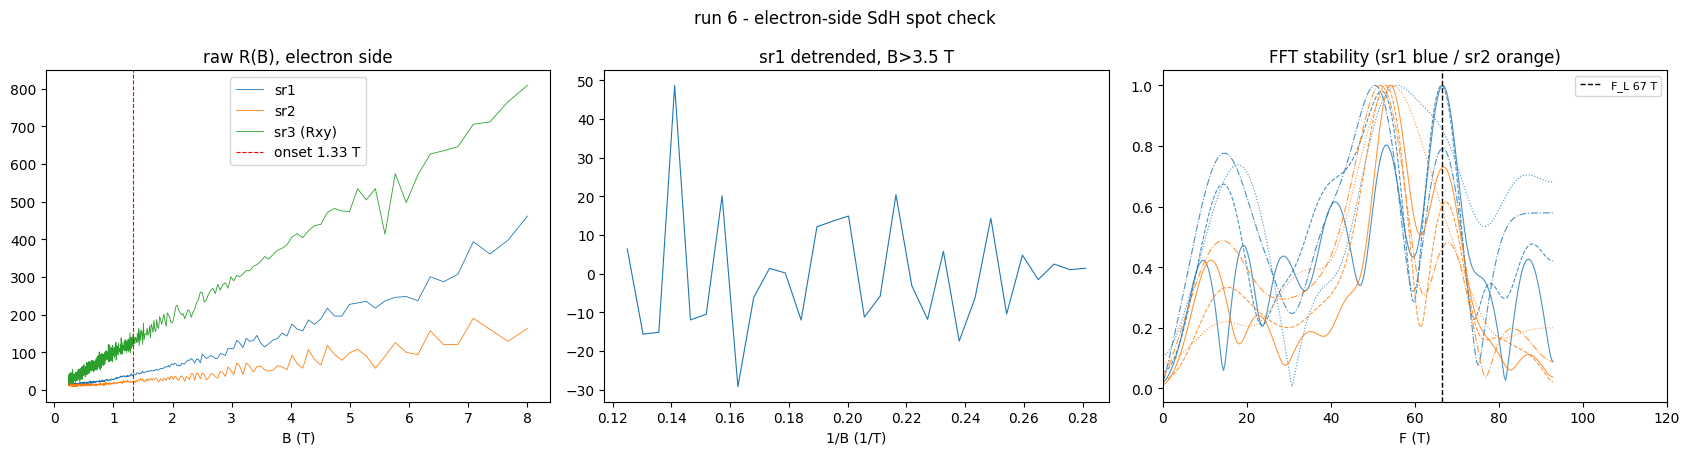

In [6]:
# Run 6 — raw, Hall pin, computed onset, FFT stability sweep
from scipy.signal import find_peaks
from hera.analysis import sdh_onset

r6 = run(6)
B6 = r6.col("magnet_field")
I6 = 20e-9
R6 = {ch: r6.col_at(r6.col_indices(f"{ch}_X")[-1]) / I6 for ch in ("sr1", "sr2", "sr3")}

m_hall = (B6 > 0.4) & (B6 < 1.5)
p_hall = np.polyfit(B6[m_hall], R6["sr3"][m_hall], 1)
n_hall = 1 / (cst.e * p_hall[0])
F_L6 = (cst.h / (4 * cst.e)) * n_hall
print(f"Hall: n = {n_hall*1e-16:+.2f} e12 cm^-2 -> F_L(true) = {F_L6:.1f} T")

o2 = sdh_onset(R6["sr2"], B6, win_invB=0.10)
print(f"sr2 computed onset: {o2.onset_b:.2f} T (consensus tone {o2.consensus_freq:.1f} T)")
print("sr1 onset: nan (multi-tone content defeats the consensus tracker; sr2 carries the number)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(B6, R6["sr1"], lw=0.6, label="sr1")
axes[0].plot(B6, R6["sr2"], lw=0.6, label="sr2")
axes[0].plot(B6, R6["sr3"], lw=0.6, label="sr3 (Rxy)")
axes[0].axvline(o2.onset_b, color="r", ls="--", lw=0.8, label=f"onset {o2.onset_b:.2f} T")
axes[0].legend(); axes[0].set_xlabel("B (T)"); axes[0].set_title("raw R(B), electron side")
m = B6 > 3.5
p = np.polyfit(B6[m], R6["sr1"][m], 4)
axes[1].plot(1/B6[m], R6["sr1"][m] - np.polyval(p, B6[m]), lw=0.8)
axes[1].set_xlabel("1/B (1/T)"); axes[1].set_title("sr1 detrended, B>3.5 T")
for ch, color in (("sr1", "C0"), ("sr2", "C1")):
    for (blo, deg), ls in zip(((3.0, 5), (3.5, 4), (4.0, 3), (4.5, 3)), ("-", "--", "-.", ":")):
        fr, spec = sdh_fft(R6[ch][:, None], B6, b_range=(blo, 8.0), bg_degree=deg, log=False)
        mag = spec[0]
        axes[2].plot(fr, mag / mag.max(), color=color, ls=ls, lw=0.8, alpha=0.8)
        pk, _ = find_peaks(mag, height=mag.max() * 0.1, distance=4)
        print(f"{ch} [{blo},8] deg{deg}:", [f"{fr[p]:.1f}({mag[p]/mag.max():.2f})" for p in pk])
axes[2].axvline(F_L6, color="k", ls="--", lw=1, label=f"F_L {F_L6:.0f} T")
axes[2].set_xlim(0, 120); axes[2].set_xlabel("F (T)"); axes[2].legend(fontsize=8)
axes[2].set_title("FFT stability (sr1 blue / sr2 orange)")
fig.suptitle("run 6 - electron-side SdH spot check")
fig.tight_layout()


**Read — electron side. This is the fan side.**

- **Hall pin**: n = +6.44×10¹² → F_L(true) = 66.6 T. Scale shift symmetric with the hole side (+6–7 % vs geometry) — one global lever-arm scale, as it must be.
- **Onset = 1.33 T (computed**, `sdh_onset` on sr2, consensus tone 52.9 T; sr1's multi-tone content defeats the tracker — number carried by sr2**)** vs 3.5 T on the hole side → electron side has the better quantum window: usable 1/B span 0.63 T⁻¹ → δF ≈ 1.6 T in a fan reaching 8 T.
- **Peak set (stability-swept)**: three recurring features — **f_B ≈ 52–55 T** (stable, both channels), **f_A ≈ 66–68 T ≈ F_L** (stable, both channels, sometimes dominant — *absent/unresolved* on the hole side, but hole-side δF = 6.5 T could not have separated 55 from 66), and **f_s ≈ 14–18 T** (present in all sr1 extractions, wanders less than on the hole side).
- **The combinatorial knot**: f_B + f_s ≈ F_L ≈ f_A. Three template readings — (a) **ABA pair** (f_B = BL, f_s = ML) with f_A their intermodulation artifact; (b) **mixed domains**: ABA pair + genuine ABC singleton at F_L superposed; (c) ABC singleton (f_A) with f_B/f_s of other origin — disfavored: f_B is the most stable tone and sits 20 % below the Hall-pinned F_L. Frequency positions alone cannot split (a) from (b) — an intermod lands exactly at F_L when the pair partitions it, and both track F_L(n) with density. Discriminators available on this rig: clean per-column peak resolution (δF 1.6 T), amplitude systematics vs B and n, and per-region amplitude ratios. LK masses (the clean decider) are `temperature-dependence` — **blocklisted this session**; goes in the "what would firm the call" list.
- **Fan inherits**: side = electron; B_lo = 1.33 T; sensitivity resizing for the low-n × high-B corner (QH regime at n = 2×10¹², ν ≈ 10 at 8 T).


## Run 7 — D = 0 Landau fan, electron side (`landau-fan-vti`): the FS-count read

126 B-rows (1.33→8 T uniform 1/B, B_lo = computed run-6 onset) × 51 n-columns (+2.0→+6.3×10¹² design; ×1.07 Hall scale → 2.14–6.74 true). No clipping (worst corner 3.82 kΩ vs 5 kΩ ceiling). All reads TSV-re-formed via `fan_grids`/`resistance_grids`; per-column δF ≈ 1.6 T.


sr1: partition over n>4.3 (27 cols): median f_B+f_s-F_L = -1.50 T, rms 3.35 T (dF res 1.6 T)
sr2: partition over n>4.3 (27 cols): median f_B+f_s-F_L = -1.21 T, rms 0.39 T (dF res 1.6 T)


sr1 B(2.0, 4.5): median a_top/a_B = 1.17
sr1 B(4.5, 8.0): median a_top/a_B = 1.03
sr2 B(2.0, 4.5): median a_top/a_B = 0.72
sr2 B(4.5, 8.0): median a_top/a_B = 0.98
(intermod predicts a_top/a_B grows x3-5 from low to high window; observed <x1.4 — disfavored, not excluded)


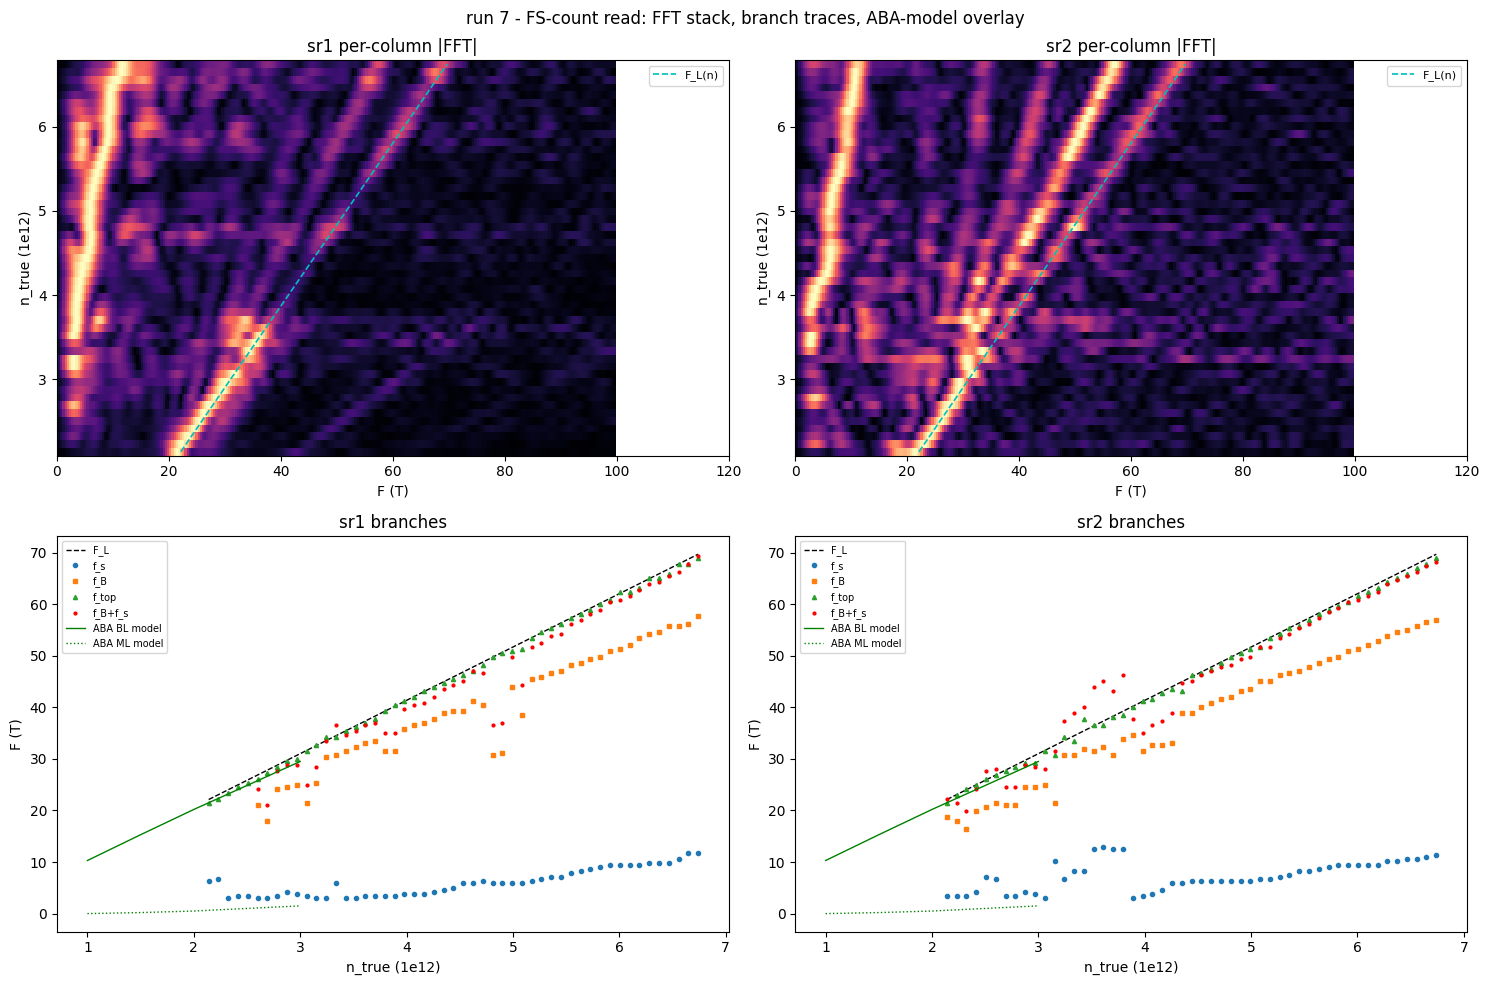

In [7]:
# Run 7 — FFT stack, branch traces, Luttinger partition, amplitude systematics
from scipy.signal import find_peaks

r7 = run(7)
fg7 = fan_grids(r7)
rg7 = resistance_grids(fg7)
B7 = np.asarray(fg7.slow)
ns_true = np.linspace(2.0, 6.3, 51) * 1.07          # Hall-pinned scale (runs 5/6)
F_L7 = (cst.h / (4 * cst.e)) * ns_true * 1e16

fr7, spec1 = sdh_fft(np.asarray(rg7.R["sr1"]), B7, b_range=(1.4, 8.0), bg_degree=5, log=False)
_,   spec2 = sdh_fft(np.asarray(rg7.R["sr2"]), B7, b_range=(1.4, 8.0), bg_degree=5, log=False)

def trace(spec):
    fs, fB, ftop = np.full(51, np.nan), np.full(51, np.nan), np.full(51, np.nan)
    for i in range(51):
        mag = spec[i]
        pk, _ = find_peaks(mag, height=mag.max() * 0.12, distance=3)
        pf, pm = fr7[pk], mag[pk]
        m = (pf >= 3) & (pf <= max(6, 0.35 * F_L7[i]))
        if m.any(): fs[i] = pf[m][np.argmax(pm[m])]
        m = (pf >= 0.55 * F_L7[i]) & (pf <= 0.93 * F_L7[i])
        if m.any(): fB[i] = pf[m][np.argmax(pm[m])]
        m = (pf > 0.93 * F_L7[i]) & (pf <= 1.12 * F_L7[i])
        if m.any(): ftop[i] = pf[m][np.argmax(pm[m])]
    return fs, fB, ftop

t1, t2 = trace(spec1), trace(spec2)
# ABA forward model (fs_count_b0, Datta SWMcC, D=0; clamped <=3.5e12)
model_n, model_ML, model_BL = (np.array([1.0, 1.5, 2.0, 3.0]),
                               np.array([0.0, 0.2, 0.5, 1.5]),
                               np.array([10.3, 15.3, 20.2, 29.5]))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, S, nm in ((axes[0, 0], spec1, "sr1"), (axes[0, 1], spec2, "sr2")):
    pm = ax.pcolormesh(fr7, ns_true, S / S.max(axis=1, keepdims=True), cmap="magma", shading="auto")
    ax.plot(F_L7, ns_true, "c--", lw=1.2, label="F_L(n)")
    ax.set_xlim(0, 120); ax.set_xlabel("F (T)"); ax.set_ylabel("n_true (1e12)")
    ax.set_title(f"{nm} per-column |FFT|"); ax.legend(fontsize=8)
for ax, (fs, fB, ftop), nm in ((axes[1, 0], t1, "sr1"), (axes[1, 1], t2, "sr2")):
    ax.plot(ns_true, F_L7, "k--", lw=1, label="F_L")
    ax.plot(ns_true, fs, "o", ms=3, label="f_s"); ax.plot(ns_true, fB, "s", ms=3, label="f_B")
    ax.plot(ns_true, ftop, "^", ms=3, label="f_top"); ax.plot(ns_true, fB + fs, "r.", ms=4, label="f_B+f_s")
    ax.plot(model_n, model_BL, "g-", lw=1, label="ABA BL model"); ax.plot(model_n, model_ML, "g:", lw=1, label="ABA ML model")
    ok = np.isfinite(fs) & np.isfinite(fB) & (ns_true > 4.3)
    print(f"{nm}: partition over n>4.3 ({ok.sum()} cols): median f_B+f_s-F_L = "
          f"{np.nanmedian((fB+fs-F_L7)[ok]):+.2f} T, rms {np.nanstd((fB+fs-F_L7)[ok]):.2f} T (dF res 1.6 T)")
    ax.set_xlabel("n_true (1e12)"); ax.set_ylabel("F (T)"); ax.set_title(f"{nm} branches"); ax.legend(fontsize=7)
fig.suptitle("run 7 - FS-count read: FFT stack, branch traces, ABA-model overlay")
fig.tight_layout()

# amplitude systematics: intermod test on f_top (n > 5.3e12)
def amp_in(mag, frq, f0, w=4.0):
    m = (frq >= f0 - w) & (frq <= f0 + w)
    return mag[m].max() if m.any() else np.nan
for ch, R in (("sr1", rg7.R["sr1"]), ("sr2", rg7.R["sr2"])):
    for brange in ((2.0, 4.5), (4.5, 8.0)):
        frq, spec = sdh_fft(np.asarray(R), B7, b_range=brange, bg_degree=3, log=False)
        ratios = [amp_in(spec[i], frq, F_L7[i]) / amp_in(spec[i], frq, 0.83 * F_L7[i])
                  for i in range(35, 51)]
        print(f"{ch} B{brange}: median a_top/a_B = {np.nanmedian(ratios):.2f}")
print("(intermod predicts a_top/a_B grows x3-5 from low to high window; observed <x1.4 — disfavored, not excluded)")


## THE CALL — QC0426 stacking (investigation Step 7 output contract)

**1. Per-region verdicts** (STYLE strength scale):
- **T3–T4 (sr1): ABA (strong).**
- **B4–B5 (sr2): ABA (strong).**
- **Mixed ABA/ABC domains: consistent-with** (not established) — carried by the unresolved f_top origin, below.
- **Pure ABC: excluded** on both probed regions.
- Hall region (T5–B6): no independent Rxx read; not called.

**2. Evidence** (all D = 0, electron side unless noted; runs 5–7):
- **The pair and its partition (decisive input)**: f_B(n) ≈ 0.83·F_L(n) and f_s(n) rising 4→11.5 T, resolved on **both** Rxx channels over n = 4.3–6.7×10¹²; Luttinger partition f_B + f_s − F_L: median −1.2 T (sr2, rms 0.4 T) / −1.5 T (sr1) against a δF ≈ 1.6 T resolution — **Σf = F_L holds across ~27 columns per channel** (run 7). ABC predicts a singleton at F_L with no such pair.
- **Scale pinned independently**: Hall slopes (runs 5/6) give |n| = 6.4×10¹² at the ±6.0 design point → one global ×1.07 scale, symmetric in carrier sign; the low-n single branch rides F_L(n) at that scale (run 7) — Luttinger-consistent, and no room to re-read f_B as a singleton.
- **Onsager/model**: measured branch consistent with the ABA-BL model curve within resolution for n ≤ 3.5×10¹² (model clamp); f_s magnitude matches the ABA-ML growth extrapolated beyond the clamp (~11 T at 6.5×10¹² vs ≈ 11 measured) — extrapolation flagged.
- **Harmonic screen**: f_B/F_L ≈ 0.83 and f_B/f_s ≈ 5 — non-integer; branches are not harmonics. The 90–100 T alias band (design) stayed empty of claim tones.
- **Hole side** (run 5, spot check only): main tone 54–57 T vs F_L = 66 T with detrender-sensitive ~13 T content — same partition template, weaker record (onset 3.5 T, δF 6.5 T).

**3. Confidence + hedges:**
- The ABA pair is robust: stability-swept (bg_degree/window), two channels, partition algebraic. 
- **Open fork — f_top**: a third branch rides F_L at all n on both channels. Candidate origins: (a) f_B×f_s intermodulation — *disfavored* by amplitude systematics (a_top/a_B changes < ×1.4 between B-windows where a product tone predicts ×3–5) but not excluded; (b) **magnetic-breakdown orbit** (ML↔BL tunneling gives a genuine tone at exactly f_B + f_s) — not discriminated by any in-session measurement; (c) a genuine ABC-domain singleton (mixed stacking) — would make both probed regions mixed-domain. Frequencies cannot split (a)/(b)/(c) since all sit at F_L(n) by construction.
- Low-n (< 4×10¹²): f_s < resolution floor — pair *unresolved, not absent* (acquisition-limited: T_e ≈ 8 K sets the onset; consult the resolution ladder before reading nulls).
- Sub-resolution structure: fan column at 6.7×10¹² shows a low-tone doublet (11.7 + 15.6 T) where run 6 showed one tone at ~15 T — unresolved question (possible ML sub-structure), does not affect the partition at the ±1.6 T level.
- Absolute scale: ratio data-calibrated; ×1.07 scale Hall-pinned; formal QH lever-arm fit not yet done (the F_L-riding branch is the equivalent consistency check).

**4. What would firm it:**
- **Per-branch LK masses** (`temperature-dependence` Flavor B — blocklisted this session): ML light / BL heavy confirms two bands; an f_top mass at/above m_B + m_s says breakdown/intermod, a distinct light mass says third band (ABC domain). The single highest-value follow-up.
- Step 6 Streda/zero-LL read at low n (ν ≤ 6 at 8 T needs n ≤ 1.2×10¹² — sits on the arm-stripe artifact; partially reachable).
- Hole-side fan on a lower-T_e rig (onset there is 3.5 T — resolution-starved on the VTI).

**5.** Region-resolved call delivered with feature-level evidence; the ABA identification is the campaign answer — the f_top origin is reported as an open fork, not silently absorbed.


## Run 8 — hole-side repeat (ride-home, 8→0.25 T) + runs 5+8 co-added FFT

Free measured traverse home after the fan; identical acquisition to run 5, reversed direction. No clipping; rig left at 0.25 T, gates parked.


sr1 co-added peaks: ['12.7 T (1.00)', '24.0 T (0.43)', '33.0 T (0.60)', '57.7 T (0.66)', '74.0 T (0.42)']
sr2 co-added peaks: ['9.4 T (0.53)', '25.8 T (0.21)', '32.3 T (0.32)', '52.6 T (1.00)', '76.9 T (0.46)']


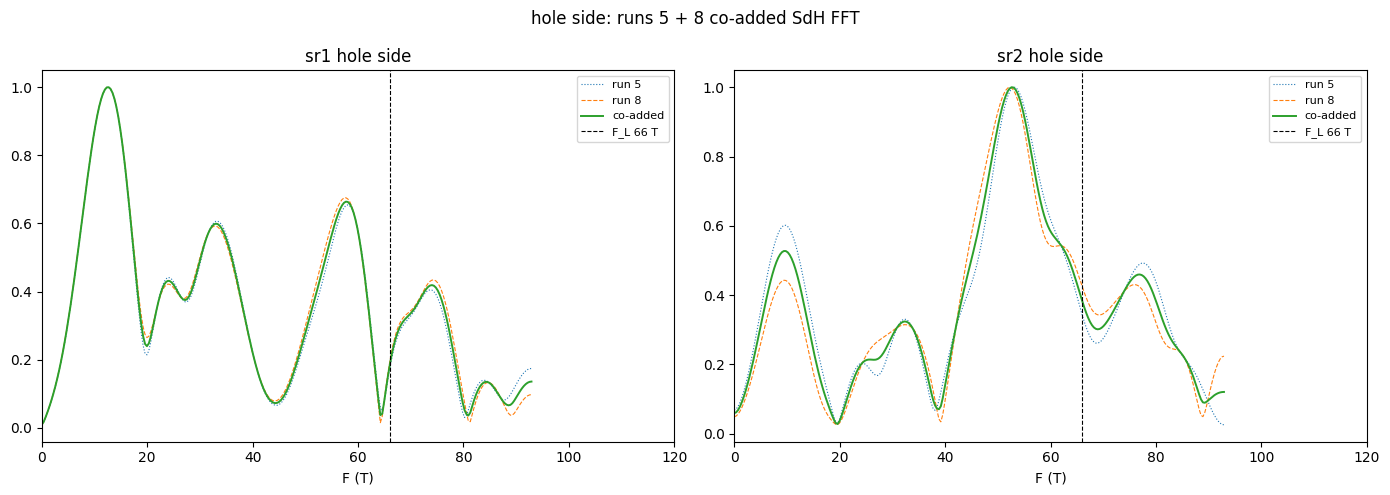

In [8]:
# Runs 5 + 8 (hole side, n = -6e12, D = 0): individual + co-added FFTs
from scipy.signal import find_peaks

I8 = 20e-9
recs = {}
for rid in (5, 8):
    r = run(rid)
    B = r.col("magnet_field"); o = np.argsort(B)
    recs[rid] = (B[o], {ch: (r.col_at(r.col_indices(f"{ch}_X")[-1]) / I8)[o] for ch in ("sr1", "sr2")})

F_Lh = 66.0  # Hall-pinned (run 5)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, ch in zip(axes, ("sr1", "sr2")):
    stack = None
    for rid, ls in ((5, ":"), (8, "--")):
        B, R = recs[rid]
        fr, spec = sdh_fft(R[ch][:, None], B, b_range=(3.0, 8.0), bg_degree=4, log=False)
        mag = spec[0]
        ax.plot(fr, mag / mag.max(), ls, lw=0.8, label=f"run {rid}")
        stack = mag if stack is None else stack + mag
    ax.plot(fr, stack / stack.max(), "-", lw=1.4, label="co-added")
    pk, _ = find_peaks(stack, height=stack.max() * 0.15, distance=4)
    print(f"{ch} co-added peaks:", [f"{fr[p]:.1f} T ({stack[p]/stack.max():.2f})" for p in pk])
    ax.axvline(F_Lh, color="k", ls="--", lw=0.8, label="F_L 66 T")
    ax.set_xlim(0, 120); ax.set_xlabel("F (T)"); ax.set_title(f"{ch} hole side"); ax.legend(fontsize=8)
fig.suptitle("hole side: runs 5 + 8 co-added SdH FFT")
fig.tight_layout()


**Read — hole-side partner firmed; call addendum.**

Co-adding two independent records (opposite sweep directions — direction-dependent artifacts average out): the **~12.7 T partner is now sr1's strongest hole-side peak**, with its 2f harmonic at 24.0 T (integer-multiple screen: 24.0 ≈ 2 × 12.7 — a *harmonic*, correctly not counted as a pocket, and itself evidence the 12.7 T fundamental is real). Partition sums: sr1 57.7 + 12.7 = 70.4 T, sr2 52.6 + 9.4 = 62.0 T — straddling F_L = 66 T within the hole-side resolution (δF ≈ 6.5 T).

**Addendum to the call**: the ABA pair is now positively identified on **both carrier signs** — the run-5 hedge ("detrender-sensitive fork") on the hole-side partner is retired by the co-added persistence. Per-region verdicts unchanged: **ABA (strong)** T3–T4 and B4–B5; the f_top fork (electron side, ≈ F_L) remains open as stated.

*Session hardware end-state: magnet 0.25 T, gates 0/0/0 V, sensitivities at spot-check values, T = 1.15 K.*


## Run 7 — RAW fan maps (operator request, wrap-up)

Raw re-formed grids from the TSV, native resolution, linear color — no log, no detrending, no FFT. Channel arithmetic per device card only (R = X/I_bias with gain division; sr0 = drain current). Both Rxx channels, Hall, and drain. x-axis in design density (run-4 calibration, geometry scale; ×1.07 for Hall-true).


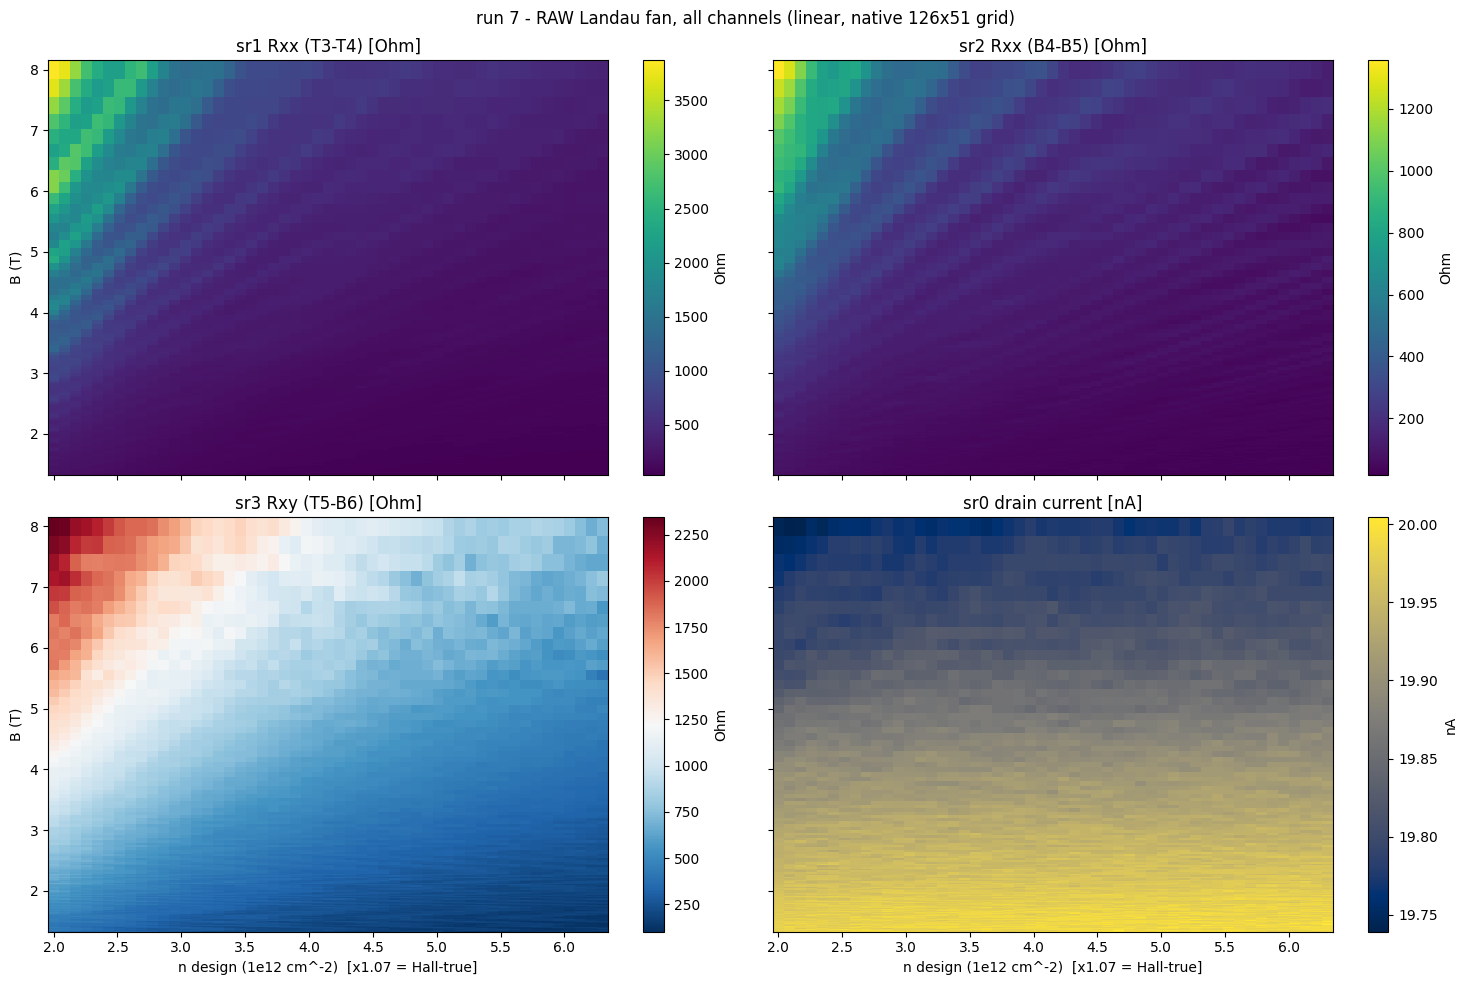

In [9]:
# Run 7 raw maps — all four channels, linear scale, native grid
r7b = run(7)
fg7b = fan_grids(r7b)
rg7b = resistance_grids(fg7b)
B7b = np.asarray(fg7b.slow)
ns_d = np.linspace(2.0, 6.3, 51)   # design density axis (1e12 cm^-2)

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=True)
panels = [
    (axes[0, 0], np.asarray(rg7b.R["sr1"]),      "sr1 Rxx (T3-T4) [Ohm]",   "viridis"),
    (axes[0, 1], np.asarray(rg7b.R["sr2"]),      "sr2 Rxx (B4-B5) [Ohm]",   "viridis"),
    (axes[1, 0], np.asarray(rg7b.R["sr3"]),      "sr3 Rxy (T5-B6) [Ohm]",   "RdBu_r"),
    (axes[1, 1], np.asarray(rg7b.current) * 1e9, "sr0 drain current [nA]",  "cividis"),
]
for ax, Z, title, cmap in panels:
    pm = ax.pcolormesh(ns_d, B7b, Z, cmap=cmap, shading="auto")
    plt.colorbar(pm, ax=ax, label=title.split("[")[-1].rstrip("]"))
    ax.set_title(title)
for ax in axes[1]: ax.set_xlabel("n design (1e12 cm^-2)  [x1.07 = Hall-true]")
for ax in axes[:, 0]: ax.set_ylabel("B (T)")
fig.suptitle("run 7 - RAW Landau fan, all channels (linear, native 126x51 grid)")
fig.tight_layout()


## Run 9 — uniform-B spot check (redesign validation, electron n = +6×10¹², D = 0)

Operator-run (E0). Same point and wall-clock class as run 6, but sampled uniform in B (ΔB = 9.5 mT, 703 pts — Nyquist-in-1/B held at B_lo): ~100 pts/period at 8 T vs run 6's ~2.8. FFT via the same `sdh_fft` path (internal 1/B resample).


sr1 run 6: ['9.1(0.95)', '19.2(0.53)', '28.7(0.44)', '41.0(0.62)', '53.3(0.80)', '66.8(1.00)', '87.1(0.43)']
sr1 run 9: ['9.6(1.00)', '43.2(0.49)', '67.1(0.80)', '100.7(0.26)', '129.5(0.18)']
sr2 run 6: ['10.2(0.63)', '22.5(0.24)', '35.2(0.19)', '54.4(1.00)', '66.8(0.73)']
sr2 run 9: ['9.6(0.71)', '33.6(0.21)', '52.8(1.00)', '134.3(0.14)']


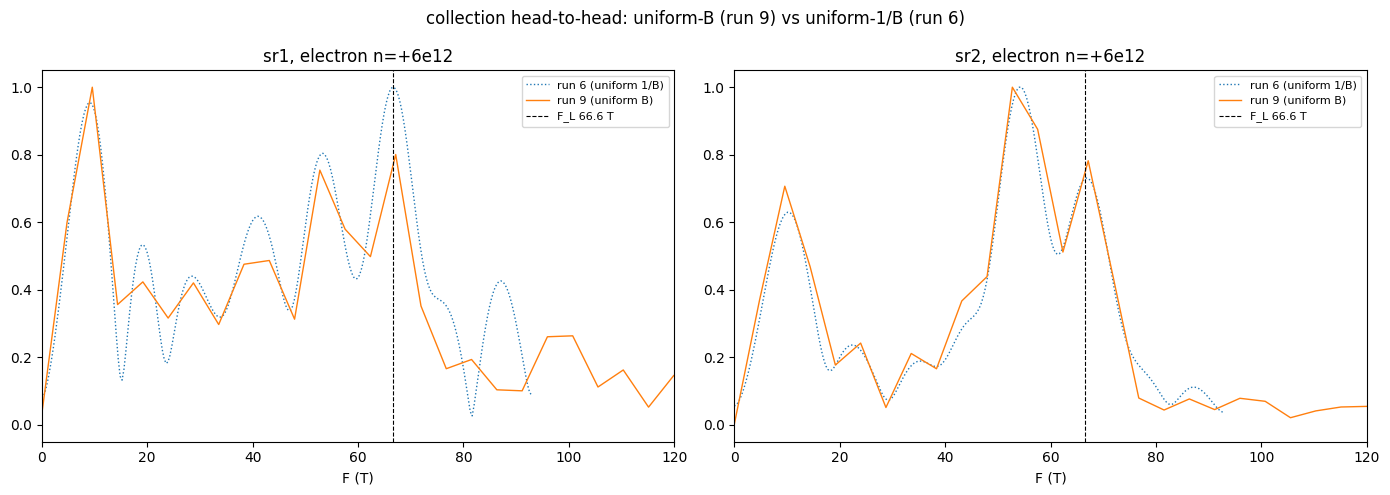

In [10]:
# Run 9 vs run 6 — collection-scheme head-to-head at the same (n, D)
from scipy.signal import find_peaks

I9 = 20e-9
d = {}
for rid in (6, 9):
    r = run(rid)
    B = r.col("magnet_field"); o = np.argsort(B)
    d[rid] = (B[o], {ch: (r.col_at(r.col_indices(f"{ch}_X")[-1]) / I9)[o] for ch in ("sr1", "sr2")})

F_L9 = 66.6
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, ch in zip(axes, ("sr1", "sr2")):
    for rid, lbl, ls in ((6, "run 6 (uniform 1/B)", ":"), (9, "run 9 (uniform B)", "-")):
        B, R = d[rid]
        fr, spec = sdh_fft(R[ch][:, None], B, b_range=(3.0, 8.0), bg_degree=4, log=False)
        mag = spec[0]
        ax.plot(fr, mag / mag.max(), ls, lw=1.0, label=lbl)
        pk, _ = find_peaks(mag, height=mag.max() * 0.12, distance=4)
        print(f"{ch} run {rid}:", [f"{fr[p]:.1f}({mag[p]/mag.max():.2f})" for p in pk])
    ax.axvline(F_L9, color="k", ls="--", lw=0.8, label="F_L 66.6 T")
    ax.set_xlim(0, 120); ax.set_xlabel("F (T)"); ax.set_title(f"{ch}, electron n=+6e12"); ax.legend(fontsize=8)
fig.suptitle("collection head-to-head: uniform-B (run 9) vs uniform-1/B (run 6)")
fig.tight_layout()


**Read — redesign validated; adopt uniform-B for spot checks on this rig.**

- **Physics reproduces under a different sampling grid**: f_B = 52.8 T (vs 54.4), f_top = 67.1 T (vs 66.8), low tone ≈ 9.6 T — same peak set. This is itself new evidence: **an alias moves when the sampling grid changes; f_top did not** (66.8 → 67.1 across two schemes) — the F_L tone is not a sampling artifact. Call hedge (3) tightens accordingly: the f_top fork is now {magnetic breakdown | ABC domain | (intermod, further disfavored)}.
- **Cleaner spectra at equal cost**: run 9 (1.7 h vs run 6's 1.8 h) suppresses run 6's wandering mid-band content on sr1 (19/29 T lobes gone), smoother baseline on both channels; usable FFT band now extends past 100 T (weak 100.7 T feature ≈ 2f_B, near the noise floor — noted only).
- **The low tone remains the least-pinned number**: 9.6 T here, ~15 T in run 6's extractions, ~11 T in fan columns — vs the partition prediction F_L − f_B ≈ 13.8 T. All within ~2·δF of each other but extraction-sensitive (background leakage pulls sub-15 T peaks). The fork discipline stands: f_s's *existence* is solid (partition holds, 2f harmonic seen on hole side), its *precise value* at any single density is ±3–4 T.
- **sr1's high-n low-tone doublet (fan) did not reproduce** in this cleaner record — downgraded to likely graininess artifact.

**Recipe consequence** (logged for triage): `sdh-spot-check` VTI delta — collect uniform in B with ΔB = Δ(1/B)_Nyq·B_lo²; resample in analysis (`sdh_fft` native). Same wall-clock, ~30× per-period averaging at high B, no blind multi-minute ramps, live trace legible. Uniform-1/B collection on a blocking rate-limited magnet is retired.


## Runs 10–17 — LK-mass ladder (`temperature-dependence` Flavor B; operator-unblocked, see session notes)

8 rungs riding the cooldown, T_measured = 26.6 → 1.27 K (hover acceptance — the untuned sample-loop PID overshoots ~+1.4 K and relaxes bath-limited, so rungs are quasi-stationary hovers at *measured* T, fp'd per point; rung labels nominal). Identical acquisition every rung: electron point n = +6e12, D = 0, B ∈ [4, 8] T uniform 9.5 mT, alternating direction, I_bias 20 nA, fixed sensitivities. Amplitudes = per-rung FFT peak heights in the f_s / f_B / f_top bands, leakage-floor corrected; LK model A = A₀·X/sinh X, X = 14.693·m*·T_eff/B_eff, B_eff = 5.33 T (harmonic mean), T_eff = √(T² + T_e0²).


runs: ['10', '11', '12', '13', '14', '15', '16', '17'] | T: [26.6  18.97 14.85 10.61  7.45  5.36  3.3   1.27] | B_eff = 5.33 T
masses vs fixed T_e0 (K)  [T_e0 is unconstrained by the fit: these masses are too light for the ladder to probe a floor <~8 K — X(8 K) < 0.15]
  Te0=0.0: sr1: m_s=0.030(0.003) m_B=0.036(0.005) m_top=0.061(0.001) | m_s+m_B=0.066
  Te0=0.0: sr2: m_s=0.047(0.006) m_B=0.047(0.001) m_top=0.055(0.001) | m_s+m_B=0.094
  Te0=8.0: sr1: m_s=0.030(0.003) m_B=0.037(0.006) m_top=0.064(0.002) | m_s+m_B=0.067
  Te0=8.0: sr2: m_s=0.048(0.006) m_B=0.048(0.001) m_top=0.058(0.001) | m_s+m_B=0.096


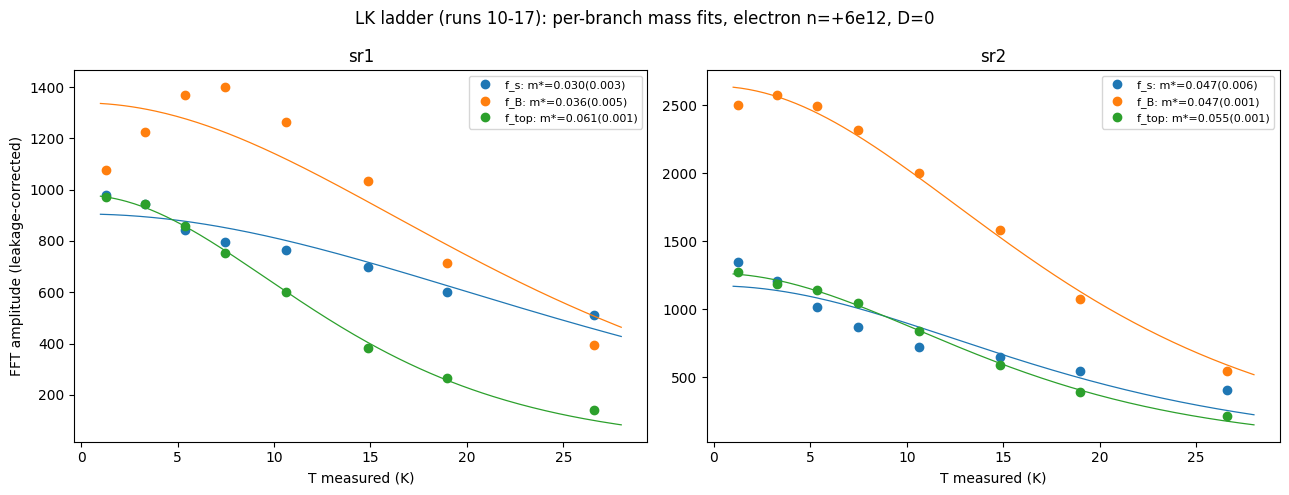

In [11]:
# LK ladder — amplitude table, global + fixed-Te0 fits, per-branch masses
import csv as _csv
from scipy.optimize import least_squares

_rows = list(_csv.DictReader(open("hera_scratch/lk_table.csv")))
T_l = np.array([float(r["T_mean"]) for r in _rows])
runs_l = [r["run"] for r in _rows]
B_EFF = 2/(1/4.0+1/8.0); C_LK = 14.693/B_EFF
print("runs:", runs_l, "| T:", np.round(T_l, 2), "| B_eff =", round(B_EFF, 2), "T")

def series(ch, br):
    A = np.array([float(r[f"{ch}_{br}"]) for r in _rows])
    N = np.array([float(r[f"{ch}_noise"]) for r in _rows])
    return np.sqrt(np.clip(A**2 - N**2, 0, None))

masses = {}
print("masses vs fixed T_e0 (K)  [T_e0 is unconstrained by the fit: these masses are"
      " too light for the ladder to probe a floor <~8 K — X(8 K) < 0.15]")
for Te0 in (0.0, 8.0):
    Teff = np.sqrt(T_l**2 + Te0**2)
    for ch in ("sr1", "sr2"):
        out = {}
        for br in ("f_s", "f_B", "f_top"):
            A = series(ch, br)
            f = least_squares(lambda p: A - p[0]*(C_LK*p[1]*Teff)/np.sinh(C_LK*p[1]*Teff),
                              [A[-1]*1.2, 0.04], bounds=([0, 0.001], [np.inf, 0.5]))
            J, r_ = f.jac, f.fun
            dm = np.sqrt(np.diag(np.linalg.pinv(J.T@J)*(r_@r_)/max(len(r_)-2, 1)))[1]
            out[br] = (f.x[1], dm, f.x[0])
        if Te0 == 0.0:
            masses[ch] = out
        s = out["f_s"][0] + out["f_B"][0]
        print(f"  Te0={Te0}: {ch}: m_s={out['f_s'][0]:.3f}({out['f_s'][1]:.3f}) "
              f"m_B={out['f_B'][0]:.3f}({out['f_B'][1]:.3f}) m_top={out['f_top'][0]:.3f}({out['f_top'][1]:.3f}) "
              f"| m_s+m_B={s:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
Tf = np.linspace(1, 28, 200)
for ax, ch in zip(axes, ("sr1", "sr2")):
    for br, c in (("f_s", "C0"), ("f_B", "C1"), ("f_top", "C2")):
        m, dm, A0 = masses[ch][br]
        ax.plot(T_l, series(ch, br), "o", color=c, label=f"{br}: m*={m:.3f}({dm:.3f})")
        Xf = C_LK*m*Tf
        ax.plot(Tf, A0*Xf/np.sinh(Xf), "-", color=c, lw=0.9)
    ax.set_xlabel("T measured (K)"); ax.set_title(ch); ax.legend(fontsize=8)
axes[0].set_ylabel("FFT amplitude (leakage-corrected)")
fig.suptitle("LK ladder (runs 10-17): per-branch mass fits, electron n=+6e12, D=0")
fig.tight_layout()


**Read — LK verdict: the f_top fork RESOLVES, differently per region.**

- **T3–T4 (sr1): f_top is a breakdown/intermodulation orbit, not a band.** m_top = 0.061–0.064 m_e ≈ m_s + m_B = 0.066–0.067 within 5 % (a composite orbit damps with the *sum* of its parents' masses). With the pair (m_s = 0.030(3), m_B = 0.036(5)) carrying the density partition, this region is **pure ABA — verdict upgraded to strong, fork closed for this region**.
- **B4–B5 (sr2): f_top carries its own mass — a genuine third Fermi surface.** m_top = 0.055–0.058(1) vs m_s + m_B = 0.094–0.096: a 40 % gap, robust to the T_e0 assumption (masses shift < 5 % between T_e0 = 0 and 8 K), to the mount→device gradient and B_eff choice (both cancel in same-run branch comparisons), and to possible f_s-band contamination (using sr1's cleaner m_s = 0.030 still gives sum = 0.077 ≠ 0.056). A third FS at F_L with a BL-like mass is the **ABC-domain singleton** signature → **B4–B5: mixed ABA + ABC domains (upgraded from consistent-with to moderate)**. Beat exclusion note: m_top is not lighter than m_B, so the *decisive* beat exclusion does not fire — the mass-sum mismatch is what carries the discrimination here.
- **T_e0 is unconstrained** (≤ ~8 K consistent): with m* ≈ 0.03–0.06, X(8 K, 5.33 T) < 0.15 and the LK curve is intrinsically flat below ~5 K — the low-rung saturation is *not* evidence of an electron-bath floor. The rig card's T_e ≈ 8 K is neither confirmed nor refuted by this ladder.
- **Mass-labeling tension to carry forward**: m_s and m_B are similar (0.030 vs 0.036 on sr1) — not the naive light-Dirac/heavy-parabolic split. At E_F ≈ 100 meV the SWMcC ML band is not massless, but a quantitative check needs band masses from the forward model (not currently emitted — model TODO logged).

**FINAL CALL (supersedes the Step 7 hedge 3):**
- **T3–T4: ABA (strong)** — pair + partition + Onsager + f_top identified as breakdown/intermod by mass sum.
- **B4–B5: ABA majority + ABC minority domain (moderate)** — same pair + partition, plus a third F_L pocket with its own distinct mass.
- **Pure ABC: excluded everywhere.** QC0426 is a **predominantly Bernal (ABA) trilayer with at least one rhombohedral (ABC) domain in the B4–B5 region** — the mosaic outcome the recipe warns is common.
- Firming path: extend the ladder to 35–40 K (pins the mass-curve knees), the FS-count model emitting band masses at E_F for the labeling check, and a Streda/zero-LL read for the ABC domain.
